# Maximal Certified Damping for Two-Scale White Initialization

This notebook studies the upper damping boundary for the reduced-CSI bootstrap certificate in `paper/sections/momentum.tex` for the two-scale white initialization
\[
\Spos_0=\sigma_{vu}^2 I_m,\qquad \Xi_0=0,\qquad \Svel_0=\sigma_{pq}^2 I_m.
\]

For each fixed \(\sigma_{vu}\), we approximate
\[
\gamma^{\mathrm{cert}}_{\max}(\sigma_{vu})
=\sup\{\gamma>0:\exists s>0\text{ such that }\mathfrak S_s(\gamma)-s<0\}.
\]

The large-damping asymptotic predicts
\[
\gamma^{\mathrm{cert}}_{\max}(\sigma_{vu})
\sim
\frac{\kappa\sigma_{vu}^3}{24e\sqrt{3\bar{\mathcal E}_0/2}},
\qquad
\bar{\mathcal E}_0=\Delta_0+\frac{m\sigma_{pq}^2}{2}.
\]


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


Matplotlib is building the font cache; this may take a moment.


In [2]:
# Problem and initialization parameters.
kappa = 1.0
L = 1.0
sigma_pq = 1.0
d_u = 1
d_v = 1
Delta0 = 1.0

# Sigma values for the main curve. The asymptotic is clearest toward the
# upper end, while the smaller values show the finite-scale mismatch.
sigma_values = np.geomspace(8.0, 250.0, 34)

# Search grids. The large-damping asymptotic has optimizer s=1/3, so the
# grid is deliberately dense on [0.02, 1.2] while retaining a logarithmic tail.
s_grid = np.unique(
    np.concatenate([
        np.geomspace(1e-6, 3.0, 1800),
        np.linspace(0.02, 1.2, 1800),
    ])
)
coarse_gamma_count = 900
bisection_steps = 36

cwd = Path.cwd()
root = next((p for p in (cwd, *cwd.parents) if (p / "code" / "figures").is_dir()), None)
if root is None:
    raise RuntimeError("Run this notebook from inside the repository")
figure_dir = root / "code" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)


## Certificate Functions

In [3]:
def Ebar0_value(*, sigma_pq=sigma_pq, d_u=d_u, d_v=d_v, Delta0=Delta0):
    m = d_u + d_v
    return Delta0 + 0.5 * m * sigma_pq**2


def certificate_arrays(gamma, s, *, sigma_vu, kappa=kappa, L=L, sigma_pq=sigma_pq, d_u=d_u, d_v=d_v, Delta0=Delta0):
    # Return gap, mathfrak_S, and lambda_s for arrays of gamma and s.
    gamma = np.asarray(gamma, dtype=float)
    s = np.asarray(s, dtype=float)
    gamma_grid, s_grid_local = np.meshgrid(gamma, s)

    Ebar0 = Ebar0_value(sigma_pq=sigma_pq, d_u=d_u, d_v=d_v, Delta0=Delta0)
    d_max = max(d_u, d_v)

    a_s = sigma_vu**2 * np.exp(-2.0 * s_grid_local)
    b_s = sigma_vu**2 * np.exp(2.0 * s_grid_local)
    mathfrak_K_s = 4.0 * a_s * kappa
    mathfrak_L_s = 4.0 * b_s * L
    rho_s = mathfrak_L_s * d_max + 2.0 * np.sqrt(2.0 * L * Ebar0)

    eps_branch_1 = 1.0 / np.sqrt(2.0 * mathfrak_L_s)
    eps_branch_2 = gamma_grid / (2.0 * (rho_s + 2.0 * gamma_grid**2))
    epsilon_s = np.minimum(eps_branch_1, eps_branch_2)

    lambda_branch_1 = 0.75 * epsilon_s * mathfrak_K_s
    lambda_branch_2 = gamma_grid
    lambda_s = (2.0 / 3.0) * np.minimum(lambda_branch_1, lambda_branch_2)

    mathfrak_S = (4.0 / lambda_s) * np.sqrt(3.0 * Ebar0 / (2.0 * a_s))
    gap = mathfrak_S - s_grid_local
    return gap, mathfrak_S, lambda_s


def min_gap_over_s(gamma, *, sigma_vu, s_grid=s_grid):
    gap, _, _ = certificate_arrays([gamma], s_grid, sigma_vu=sigma_vu)
    column = gap[:, 0]
    idx = int(np.nanargmin(column))
    return float(column[idx]), float(s_grid[idx])


def has_certified_window(gamma, *, sigma_vu, s_grid=s_grid):
    min_gap, s_star = min_gap_over_s(gamma, sigma_vu=sigma_vu, s_grid=s_grid)
    return min_gap < 0.0, min_gap, s_star


def gamma_max_asymptotic(sigma_vu, *, kappa=kappa, sigma_pq=sigma_pq, d_u=d_u, d_v=d_v, Delta0=Delta0):
    Ebar0 = Ebar0_value(sigma_pq=sigma_pq, d_u=d_u, d_v=d_v, Delta0=Delta0)
    C0 = np.sqrt(3.0 * Ebar0 / 2.0)
    sigma_vu = np.asarray(sigma_vu, dtype=float)
    return kappa * sigma_vu**3 / (24.0 * np.e * C0)


## Grid and Refined Upper Boundary

The coarse estimate is the largest \(\gamma\) on a logarithmic grid for which some \(s\)-grid point has negative bootstrap gap. The refined estimate brackets the upper boundary found by the coarse grid and then bisects in \(\gamma\), while continuing to test nonemptiness by minimizing over the same \(s\)-grid.


In [4]:
def coarse_gamma_scan(sigma_vu, *, upper_factor=8.0, lower_factor=1e-4):
    predicted = float(gamma_max_asymptotic(sigma_vu))
    lower = max(1e-10, predicted * lower_factor)
    upper = max(1.0, predicted * upper_factor)

    # Expand until the coarse grid sees a false point beyond the last true point.
    for _ in range(8):
        gamma_grid = np.geomspace(lower, upper, coarse_gamma_count)
        gap, _, _ = certificate_arrays(gamma_grid, s_grid, sigma_vu=sigma_vu)
        nonempty = np.any(gap < 0.0, axis=0)
        if np.any(nonempty) and not nonempty[-1]:
            break
        upper *= 3.0
    else:
        gamma_grid = np.geomspace(lower, upper, coarse_gamma_count)
        gap, _, _ = certificate_arrays(gamma_grid, s_grid, sigma_vu=sigma_vu)
        nonempty = np.any(gap < 0.0, axis=0)

    if not np.any(nonempty):
        return {
            "gamma_grid": gamma_grid,
            "nonempty": nonempty,
            "gamma_coarse": np.nan,
            "bracket": (np.nan, np.nan),
        }

    true_indices = np.flatnonzero(nonempty)
    last_true = int(true_indices[-1])
    gamma_coarse = float(gamma_grid[last_true])

    if last_true + 1 < len(gamma_grid):
        bracket = (float(gamma_grid[last_true]), float(gamma_grid[last_true + 1]))
    else:
        hi = float(gamma_grid[-1])
        while has_certified_window(hi, sigma_vu=sigma_vu)[0]:
            hi *= 2.0
        bracket = (float(gamma_grid[last_true]), hi)

    return {
        "gamma_grid": gamma_grid,
        "nonempty": nonempty,
        "gamma_coarse": gamma_coarse,
        "bracket": bracket,
    }


def refine_gamma_max(sigma_vu, bracket, *, steps=bisection_steps):
    lo, hi = bracket
    if not (np.isfinite(lo) and np.isfinite(hi)):
        return np.nan, np.nan, np.nan

    # Keep the invariant: lo is certified, hi is not certified.
    lo_ok, _, _ = has_certified_window(lo, sigma_vu=sigma_vu)
    hi_ok, _, _ = has_certified_window(hi, sigma_vu=sigma_vu)
    if not lo_ok:
        return np.nan, np.nan, np.nan
    while hi_ok:
        hi *= 2.0
        hi_ok, _, _ = has_certified_window(hi, sigma_vu=sigma_vu)

    best_gap = np.nan
    best_s = np.nan
    for _ in range(steps):
        mid = np.sqrt(lo * hi)
        ok, min_gap, s_star = has_certified_window(mid, sigma_vu=sigma_vu)
        if ok:
            lo = mid
            best_gap = min_gap
            best_s = s_star
        else:
            hi = mid
    return float(lo), float(best_gap), float(best_s)


In [5]:
rows = []
for sigma_vu in sigma_values:
    scan = coarse_gamma_scan(float(sigma_vu))
    gamma_refined, boundary_gap, boundary_s = refine_gamma_max(float(sigma_vu), scan["bracket"])
    rows.append({
        "sigma_vu": float(sigma_vu),
        "gamma_asymptotic": float(gamma_max_asymptotic(sigma_vu)),
        "gamma_grid": scan["gamma_coarse"],
        "gamma_refined": gamma_refined,
        "boundary_gap": boundary_gap,
        "boundary_s": boundary_s,
    })

print("sigma_vu    gamma_grid      gamma_refined   gamma_asymptotic   refined/asymptotic   s_at_boundary")
for row in rows[:: max(1, len(rows)//8)]:
    print(
        f"{row['sigma_vu']:8.3g}  "
        f"{row['gamma_grid']:12.5g}  "
        f"{row['gamma_refined']:13.5g}  "
        f"{row['gamma_asymptotic']:16.5g}  "
        f"{row['gamma_refined'] / row['gamma_asymptotic']:18.5g}  "
        f"{row['boundary_s']:13.5g}"
    )


sigma_vu    gamma_grid      gamma_refined   gamma_asymptotic   refined/asymptotic   s_at_boundary
       8           nan            nan            4.5311                 nan            nan
    12.1           nan            nan            15.841                 nan            nan
    18.4           nan            nan            55.382                 nan            nan
      28         176.4         176.68            193.62              0.9125        0.31516
    42.4        664.99         666.41            676.91             0.98449        0.33025
    64.4        2354.2         2359.7            2366.5             0.99711        0.33287
    97.8        8230.6         8269.1            8273.6             0.99946        0.33344
     148         28775          28922             28925              0.9999        0.33344
     225     1.006e+05     1.0112e+05        1.0112e+05             0.99998        0.33344


## Plot of the Maximal Certified Damping

PosixPath('/Users/gpeyre/Dropbox/github/linear-network-global/python/figures/momentum_gamma_cert_max_vs_sigma.pdf')

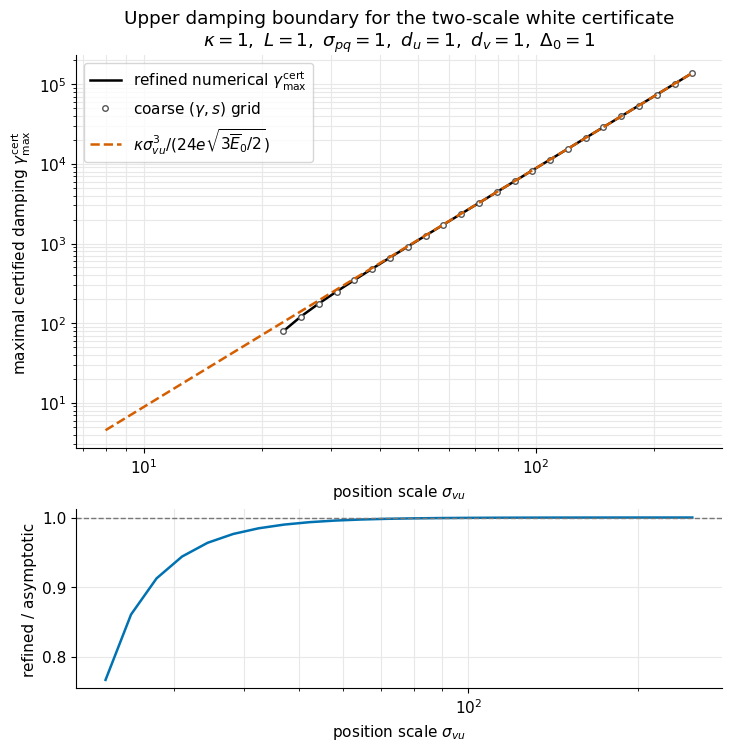

In [6]:
sigma_curve = np.asarray([row["sigma_vu"] for row in rows])
gamma_asym_curve = np.asarray([row["gamma_asymptotic"] for row in rows])
gamma_grid_curve = np.asarray([row["gamma_grid"] for row in rows])
gamma_refined_curve = np.asarray([row["gamma_refined"] for row in rows])
s_boundary_curve = np.asarray([row["boundary_s"] for row in rows])

fig, axes = plt.subplots(
    2,
    1,
    figsize=(7.2, 7.4),
    constrained_layout=True,
    gridspec_kw={"height_ratios": [2.2, 1.0]},
)
ax = axes[0]
ax.loglog(
    sigma_curve,
    gamma_refined_curve,
    color="black",
    linewidth=1.8,
    label=r"refined numerical $\gamma^{\mathrm{cert}}_{\max}$",
)
ax.loglog(
    sigma_curve,
    gamma_grid_curve,
    marker="o",
    linestyle="none",
    markersize=4.0,
    markerfacecolor="white",
    markeredgecolor="#555555",
    label=r"coarse $(\gamma,s)$ grid",
)
ax.loglog(
    sigma_curve,
    gamma_asym_curve,
    color="#D55E00",
    linewidth=1.8,
    linestyle="--",
    label=r"$\kappa\sigma_{vu}^3/(24e\sqrt{3\overline{E}_0/2})$",
)
ax.set_xlabel(r"position scale $\sigma_{vu}$")
ax.set_ylabel(r"maximal certified damping $\gamma^{\mathrm{cert}}_{\max}$")
ax.set_title(
    r"Upper damping boundary for the two-scale white certificate"
    "\n"
    rf"$\kappa={kappa:g},\ L={L:g},\ \sigma_{{pq}}={sigma_pq:g},\ "
    rf"d_u={d_u},\ d_v={d_v},\ \Delta_0={Delta0:g}$"
)
ax.grid(True, which="both", color="#E8E8E8", linewidth=0.8)
ax.legend(loc="best")

ratio = gamma_refined_curve / gamma_asym_curve
axes[1].semilogx(sigma_curve, ratio, color="#0072B2", linewidth=1.8)
axes[1].axhline(1.0, color="#777777", linewidth=1.0, linestyle="--")
axes[1].set_xlabel(r"position scale $\sigma_{vu}$")
axes[1].set_ylabel(r"refined / asymptotic")
axes[1].grid(True, which="both", color="#E8E8E8", linewidth=0.8)

output = figure_dir / "momentum_gamma_cert_max_vs_sigma.pdf"
fig.savefig(output, dpi=200)
output


## Verification at Test Damping Values

For several test scales, we probe dampings at fixed multiples of the asymptotic boundary. A point is marked certified if the direct \(s\)-grid search finds \(\min_s\mathfrak G_s(\gamma)<0\).


In [7]:
test_sigmas = np.asarray([15.0, 30.0, 60.0, 120.0, 240.0])
test_factors = np.asarray([0.6, 0.9, 1.1, 1.4])

test_rows = []
for sigma_vu in test_sigmas:
    gamma_pred = float(gamma_max_asymptotic(sigma_vu))
    for factor in test_factors:
        gamma_value = factor * gamma_pred
        ok, min_gap, s_star = has_certified_window(gamma_value, sigma_vu=sigma_vu)
        test_rows.append({
            "sigma_vu": sigma_vu,
            "factor": factor,
            "gamma": gamma_value,
            "certified": ok,
            "min_gap": min_gap,
            "s_star": s_star,
        })

print("sigma_vu  factor  gamma          certified  min_gap       s_star")
for row in test_rows:
    print(
        f"{row['sigma_vu']:8.3g}  "
        f"{row['factor']:6.2f}  "
        f"{row['gamma']:12.5g}  "
        f"{str(row['certified']):>9s}  "
        f"{row['min_gap']:11.4g}  "
        f"{row['s_star']:10.4g}"
    )


sigma_vu  factor  gamma          certified  min_gap       s_star
      15    0.60        17.921      False       0.1676     0.06854
      15    0.90        26.881      False       0.1627     0.09615
      15    1.10        32.855      False       0.1751      0.0974
      15    1.40        41.815      False       0.2044     0.08421
      30    0.60        143.37       True      -0.1082      0.4083
      30    0.90        215.05       True     -0.01061      0.3289
      30    1.10        262.84      False       0.0467      0.2771
      30    1.40        334.52      False       0.1202      0.2079
      60    0.60        1146.9       True      -0.1654      0.4955
      60    0.90        1720.4       True     -0.03344      0.3657
      60    1.10        2102.7      False      0.03276      0.3001
      60    1.40        2676.2      False       0.1127      0.2203
     120    0.60        9175.5       True        -0.17      0.5034
     120    0.90         13763       True     -0.03501      0.36

PosixPath('/Users/gpeyre/Dropbox/github/linear-network-global/python/figures/momentum_gamma_cert_max_tests.pdf')

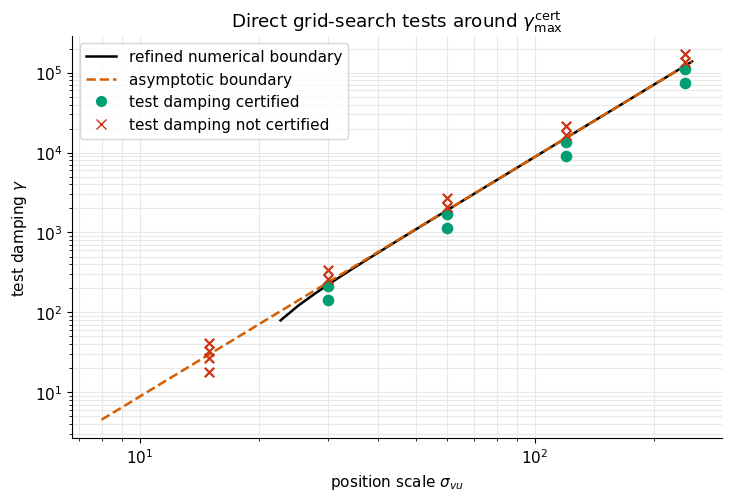

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 4.9), constrained_layout=True)
ax.loglog(
    sigma_curve,
    gamma_refined_curve,
    color="black",
    linewidth=1.8,
    label=r"refined numerical boundary",
)
ax.loglog(
    sigma_curve,
    gamma_asym_curve,
    color="#D55E00",
    linewidth=1.8,
    linestyle="--",
    label=r"large-damping asymptotic",
)

for row in test_rows:
    color = "#009E73" if row["certified"] else "#CC3311"
    marker = "o" if row["certified"] else "x"
    ax.scatter(
        row["sigma_vu"],
        row["gamma"],
        color=color,
        marker=marker,
        s=46,
        linewidths=1.6,
        zorder=3,
    )

handles = [
    Line2D([0], [0], color="black", linewidth=1.8, label=r"refined numerical boundary"),
    Line2D([0], [0], color="#D55E00", linewidth=1.8, linestyle="--", label=r"asymptotic boundary"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#009E73", markeredgecolor="#009E73", markersize=7, label="test damping certified"),
    Line2D([0], [0], marker="x", color="#CC3311", linestyle="none", markersize=7, label="test damping not certified"),
]
ax.legend(handles=handles, loc="best")
ax.set_xlabel(r"position scale $\sigma_{vu}$")
ax.set_ylabel(r"test damping $\gamma$")
ax.set_title(r"Direct grid-search tests around $\gamma^{\mathrm{cert}}_{\max}$")
ax.grid(True, which="both", color="#E8E8E8", linewidth=0.8)

output = figure_dir / "momentum_gamma_cert_max_tests.pdf"
fig.savefig(output, dpi=200)
output


## Boundary Optimizer Sanity Check

In the asymptotic large-damping calculation, the maximizing budget is \(s=1/3\). The refined numerical boundary should approach this value as \(\sigma_{vu}\) grows.


PosixPath('/Users/gpeyre/Dropbox/github/linear-network-global/python/figures/momentum_gamma_cert_max_boundary_s.pdf')

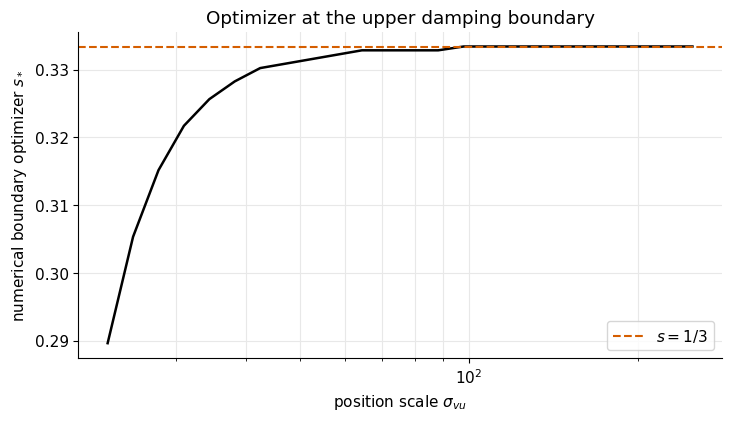

In [9]:
fig, ax = plt.subplots(figsize=(7.2, 4.1), constrained_layout=True)
ax.semilogx(sigma_curve, s_boundary_curve, color="black", linewidth=1.8)
ax.axhline(1.0 / 3.0, color="#D55E00", linewidth=1.5, linestyle="--", label=r"$s=1/3$")
ax.set_xlabel(r"position scale $\sigma_{vu}$")
ax.set_ylabel(r"numerical boundary optimizer $s_*$")
ax.set_title(r"Optimizer at the upper damping boundary")
ax.grid(True, which="both", color="#E8E8E8", linewidth=0.8)
ax.legend(loc="best")

output = figure_dir / "momentum_gamma_cert_max_boundary_s.pdf"
fig.savefig(output, dpi=200)
output
